# Business Analytics

**Tema:** Analítica Prescriptiva para la Prevención de la Violencia Intrafamiliar en Colombia (2015-2024).

**Nivel:** 9.º Semestre - Ingeniería de Sistemas.

**Dataset:** Violencia intrafamiliar. Colombia, años 2015 a 2024.

**Integrantes:**
- Martin Daniel Montaño Bautista
- Johan Sneider Cortes Bernal

## Objetivos de la Sesión

1. **Analítica Prescriptiva:** formular recomendaciones a partir de los patrones identificados en los registros de violencia intrafamiliar.
2. **Priorización Territorial:** identificar departamentos que requieren seguimiento según el volumen de registros y su comportamiento temporal.
3. **Construcción de Escenarios:** reconocer características recurrentes que permitan orientar estrategias de prevención.
4. **Toma de Decisiones:** establecer acciones que puedan ser consideradas por instituciones y entidades responsables de la atención social.
5. **Evaluación Estratégica:** proponer indicadores que permitan realizar seguimiento a las acciones recomendadas.

## Metodología

- Carga y preparación de los datos.
- Identificación de territorios prioritarios.
- Análisis de patrones relevantes para la intervención.
- Construcción de escenarios de actuación.
- Diseño de una matriz de decisiones.
- Formulación de recomendaciones y conclusiones.

In [ ]:
# ==========================================
# 0. CONFIGURACIÓN DEL ENTORNO Y CARGA DE DATOS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 6)

pd.set_option("display.max_columns", None)

# Descargar dataset
url_api = (
    "https://www.datos.gov.co/resource/ers2-kerr.csv"
    "?$limit=500000"
)

df_original = pd.read_csv(url_api)

# Crear copia de trabajo
df_clean = df_original.copy()

# Normalización de textos
columnas_texto = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for columna in columnas_texto:

    df_clean[columna] = (
        df_clean[columna]
        .astype("string")
        .str.strip()
    )

# Normalización de variables temporales
for columna in ["mes_del_hecho", "dia_del_hecho"]:

    df_clean[columna] = (
        df_clean[columna]
        .str.lower()
        .str.capitalize()
    )

df_clean["a_o_del_hecho"] = pd.to_numeric(
    df_clean["a_o_del_hecho"],
    errors="coerce"
)

print("Base preparada para el análisis prescriptivo.")
print("Dimensiones:", df_clean.shape)

display(df_clean.head())

Base preparada para el análisis prescriptivo.
Dimensiones: (236840, 36)


,id,a_o_del_hecho,sexo_de_la_victima,grupo_de_edad_quinquenal,grupo_mayor_menor_de_edad,grupo_de_edad_judicial,ciclo_vital,pais_de_nacimiento,escolaridad,estado_civil,tipo_de_discapacidad,pertenencia_etnica,orientacion_sexual,identidad_de_genero,transgenero,pertenencia_grupal,mes_del_hecho,dia_del_hecho,rango_de_hora_del_hecho_x_3_horas,codigo_dane_municipio,municipio_del_hecho_dane,departamento_del_hecho_dane,codigo_dane_departamento,localidad_del_hecho,zona_del_hecho,escenario_del_hecho,actividad_durante_el_hecho,circunstancia_del_hecho_detallada,contexto_del_hecho,mecanismo_causal_de_la_lesion_no_fatal,diagnostico_topografico_de_la_lesion_no_fatal,sexo_del_agresor,presunto_agresor_detallado,factor_desencadenante_de_la_agresion,dias_de_incapacidad_medicolegal,pueblo_indigena
0,1,2015,Hombre,(10 a 14),a) Menor de Edad (<18 Años),(10 a 13),(12 a 17) Adolescencia,Colombia,Básica primaria,Soltero (a),Ninguna,Sin información,No Sabe / No Informa,No Sabe / No Informa,No Sabe / No Informa,Sin información,Diciembre,Martes,(18:00 a 20:59),11001,"Bogotá, D.C.","Bogotá, D.C.",11,Rafael Uribe Uribe,Cabecera municipal,"Calle (Autopista,Avenida,Dentro de La Ciudad)",Actividades de desplazamiento de un lugar a otro.,"Violencia contra niños, niñas y adolescentes","3 Lesiones no Fatales contra Niños, Niñas y Ad...",Abrasivo,Trauma de miembros,Hombre,Padre,"Intolerancia, machismo",1 a 30,No había sido implementada
1,2,2015,Hombre,(00 a 04),a) Menor de Edad (<18 Años),(00 a 04),(00 a 05) Primera Infancia,Colombia,No aplica,No aplica,Ninguna,Sin pertenencia étnica,No aplica,No aplica,No aplica,Sin información,Marzo,Miércoles,(18:00 a 20:59),25754,Soacha,Cundinamarca,25,Sin información,Cabecera municipal,Vivienda,Actividades relacionadas con la asistencia a e...,"Violencia contra niños, niñas y adolescentes","3 Lesiones no Fatales contra Niños, Niñas y Ad...",Contundente,Trauma de miembros,Mujer,Madre,"Intolerancia, machismo",1 a 30,No había sido implementada
2,3,2015,Hombre,(00 a 04),a) Menor de Edad (<18 Años),(00 a 04),(00 a 05) Primera Infancia,Colombia,No aplica,No aplica,Ninguna,Sin pertenencia étnica,No aplica,No aplica,No aplica,Sin información,Junio,Jueves,Sin información,25754,Soacha,Cundinamarca,25,Sin información,Cabecera municipal,Sin información,Actividades de desplazamiento de un lugar a otro.,"Violencia contra niños, niñas y adolescentes","3 Lesiones no Fatales contra Niños, Niñas y Ad...",Por determinar,Sin información,Mujer,Otros familiares civiles o consanguineos,"Intolerancia, machismo",Sin información,No había sido implementada
3,4,2015,Hombre,(00 a 04),a) Menor de Edad (<18 Años),(00 a 04),(00 a 05) Primera Infancia,Colombia,No aplica,No aplica,Ninguna,Sin pertenencia étnica,No aplica,No aplica,No aplica,Sin información,Enero,Sábado,(06:00 a 08:59),54001,Cúcuta,Norte de Santander,54,Sin información,Cabecera municipal,Vivienda,Actividades de desplazamiento de un lugar a otro.,"Violencia contra niños, niñas y adolescentes","3 Lesiones no Fatales contra Niños, Niñas y Ad...",Contundente,Trauma facial,Mujer,Abuelo (a),"Intolerancia, machismo",1 a 30,No había sido implementada
4,5,2015,Hombre,(25 a 29),b) Mayor de Edad (>18 Años),(25 a 28),(18 a 28) Juventud,Colombia,Sin información,Unión libre,Ninguna,Sin información,Heterosexual,No Sabe / No Informa,No Sabe / No Informa,Sin información,Mayo,Martes,(09:00 a 11:59),11001,"Bogotá, D.C.","Bogotá, D.C.",11,Usme,Cabecera municipal,"Calle (Autopista,Avenida,Dentro de La Ciudad)",Actividades de desplazamiento de un lugar a otro.,Violencia entre otros familiares,4 Lesiones no Fatales por Violencia entre otro...,Contundente,Trauma facial,Hombre,Hermano (a),"Intolerancia, machismo",1 a 30,No había sido implementada


**Configuración del Entorno y Carga de Datos**

Se importan las librerías necesarias para realizar el análisis y generar visualizaciones.

Se obtiene nuevamente el dataset desde la API de Datos Abiertos Colombia, garantizando que esta fase pueda ejecutarse de manera independiente.

Se realiza una preparación básica de la información mediante:

- Normalización de espacios en las variables de texto.
- Estandarización de los nombres de meses y días.
- Conversión de la variable año a formato numérico.
- Creación de una copia de trabajo.

Esta información servirá como base para construir indicadores de priorización y formular recomendaciones.

---
## 1. Analítica Prescriptiva: ¿Qué decisiones podemos tomar?

La analítica prescriptiva utiliza los resultados de las fases anteriores para proponer acciones y estrategias que permitan mejorar la toma de decisiones.

En este proyecto se busca transformar los patrones encontrados en los registros de violencia intrafamiliar en propuestas de prevención y atención.

### Preguntas orientadoras

- ¿Qué departamentos deberían recibir mayor atención institucional según el volumen de registros?
- ¿Qué territorios presentan incrementos que requieren seguimiento?
- ¿Qué características recurrentes deberían considerarse en las estrategias de prevención?
- ¿Qué acciones podrían implementarse según los grupos poblacionales y escenarios identificados?
- ¿Cómo se pueden establecer mecanismos de seguimiento a las estrategias propuestas?

### Proceso prescriptivo

1. Identificación de territorios prioritarios.
2. Análisis de características recurrentes.
3. Construcción de escenarios de intervención.
4. Diseño de recomendaciones.
5. Establecimiento de indicadores de seguimiento.

Las recomendaciones se plantearán como propuestas de actuación institucional y no como intervenciones cuya efectividad ya haya sido demostrada por el dataset.

In [ ]:
# ==========================================
# 1.1 PRIORIZACIÓN TERRITORIAL
# ==========================================

col_departamento = "departamento_del_hecho_dane"
col_anio = "a_o_del_hecho"

# Agrupar registros por departamento y año
registros_territoriales = (
    df_clean
    .dropna(subset=[col_departamento, col_anio])
    .groupby([col_departamento, col_anio])
    .size()
    .reset_index(name="Registros")
)

# Crear tabla de comportamiento anual
tabla_territorial = registros_territoriales.pivot(
    index=col_departamento,
    columns=col_anio,
    values="Registros"
).fillna(0)

tabla_territorial = tabla_territorial.sort_index(axis=1)

# Identificar los dos últimos años disponibles
anios_disponibles = sorted(tabla_territorial.columns)

anio_actual = anios_disponibles[-1]

anio_anterior = (
    anios_disponibles[-2]
    if len(anios_disponibles) >= 2
    else None
)

# Construir resumen territorial
resumen_territorial = pd.DataFrame(index=tabla_territorial.index)

resumen_territorial["Registros_año_actual"] = (
    tabla_territorial[anio_actual]
)

if anio_anterior is not None:

    resumen_territorial["Registros_año_anterior"] = (
        tabla_territorial[anio_anterior]
    )

    resumen_territorial["Variacion_porcentual"] = np.where(
        resumen_territorial["Registros_año_anterior"] > 0,

        (
            (
                resumen_territorial["Registros_año_actual"]
                - resumen_territorial["Registros_año_anterior"]
            )
            / resumen_territorial["Registros_año_anterior"]
        ) * 100,

        np.nan
    )

else:

    resumen_territorial["Registros_año_anterior"] = np.nan
    resumen_territorial["Variacion_porcentual"] = np.nan

resumen_territorial = (
    resumen_territorial
    .reset_index()
    .rename(columns={
        col_departamento: "Codigo_departamento"
    })
)

# Porcentaje de participación nacional
total_actual = resumen_territorial[
    "Registros_año_actual"
].sum()

resumen_territorial["Participacion_porcentual"] = (
    resumen_territorial["Registros_año_actual"]
    / total_actual * 100
).round(2)

# Clasificar niveles de atención por volumen
umbral_alto = resumen_territorial[
    "Registros_año_actual"
].quantile(0.75)

def clasificar_prioridad(fila):

    volumen = fila["Registros_año_actual"]
    variacion = fila["Variacion_porcentual"]

    if volumen >= umbral_alto and pd.notna(variacion) and variacion > 0:
        return "Alta: volumen y crecimiento"

    elif volumen >= umbral_alto:
        return "Alta: volumen de registros"

    elif pd.notna(variacion) and variacion > 0:
        return "Seguimiento: crecimiento"

    else:
        return "Seguimiento general"

resumen_territorial["Nivel_atencion"] = (
    resumen_territorial.apply(
        clasificar_prioridad,
        axis=1
    )
)

# Ordenar resultados
resumen_territorial = resumen_territorial.sort_values(
    "Registros_año_actual",
    ascending=False
)

print("Año más reciente:", anio_actual)
print("Año de comparación:", anio_anterior)

display(resumen_territorial.head(15))

Año más reciente: 2024
Año de comparación: 2023


,Codigo_departamento,Registros_año_actual,Registros_año_anterior,Variacion_porcentual,Participacion_porcentual,Nivel_atencion
5,"Bogotá, D.C.",4944.0,5861.0,-15.645794,24.49,Alta: volumen de registros
1,Antioquia,2643.0,3252.0,-18.726937,13.09,Alta: volumen de registros
14,Cundinamarca,1877.0,2115.0,-11.252955,9.30,Alta: volumen de registros
32,Valle del Cauca,1243.0,1618.0,-23.176761,6.16,Alta: volumen de registros
4,Atlántico,922.0,1047.0,-11.938873,4.57,Alta: volumen de registros
28,Santander,899.0,1030.0,-12.718447,4.45,Alta: volumen de registros
7,Boyacá,777.0,835.0,-6.946108,3.85,Alta: volumen de registros
31,Tolima,773.0,1011.0,-23.541048,3.83,Alta: volumen de registros
23,Norte de Santander,609.0,505.0,20.594059,3.02,Alta: volumen y crecimiento
18,Huila,513.0,544.0,-5.698529,2.54,Seguimiento general


**Priorización Territorial**

En esta sección se construye un indicador de seguimiento territorial utilizando la cantidad de registros por departamento y año.

Se realizan los siguientes procedimientos:

- Agrupación de los registros por departamento y año.
- Construcción de una tabla comparativa temporal.
- Identificación del año más reciente y del año inmediatamente anterior disponibles.
- Cálculo de la variación porcentual entre ambos periodos.
- Cálculo de la participación de cada departamento sobre el total nacional del año más reciente.

Posteriormente, se establecen niveles de atención:

1. **Alta: volumen y crecimiento:** territorios que presentan una cantidad elevada de registros y un incremento respecto al periodo anterior.
2. **Alta: volumen de registros:** territorios con una concentración elevada de registros.
3. **Seguimiento: crecimiento:** territorios que presentan incrementos, aunque su volumen no se encuentre entre los más altos.
4. **Seguimiento general:** territorios que no cumplen las condiciones anteriores.

Se utiliza el percentil 75 como referencia para identificar los departamentos con mayor volumen de registros.

**Consideración metodológica:** esta clasificación representa una priorización operativa basada en cantidades registradas. No constituye un índice de riesgo poblacional ni una medición de incidencia, ya que no se dispone de denominadores de población para calcular tasas comparables.

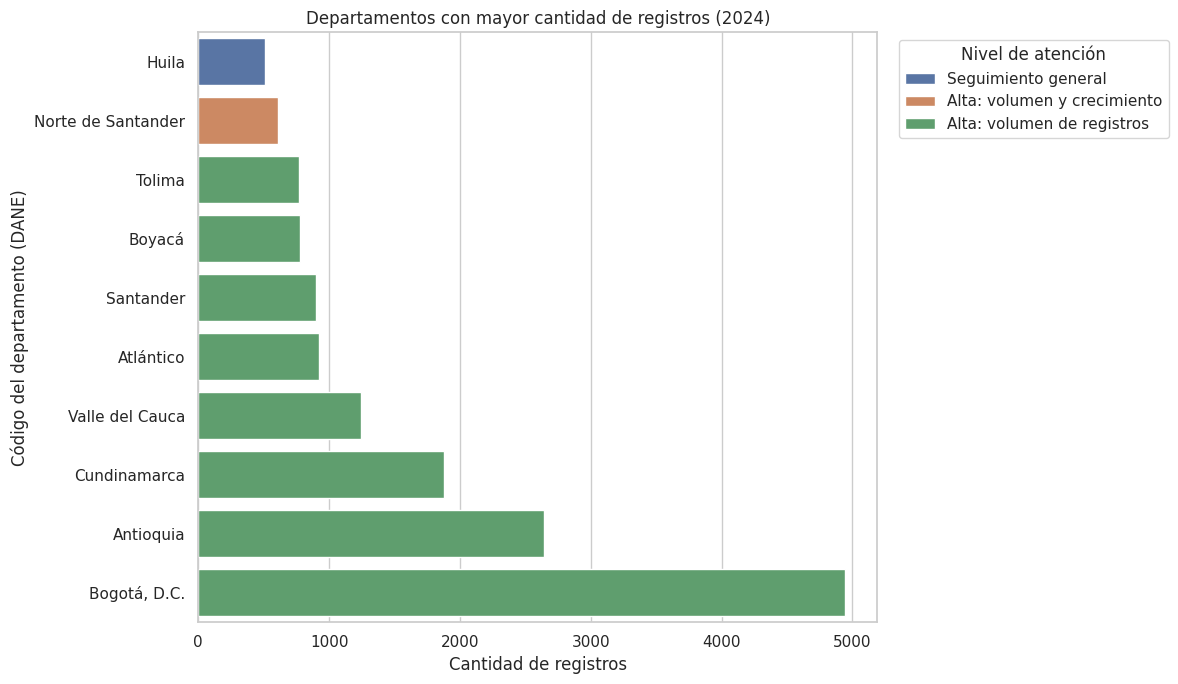

,Codigo_departamento,Registros_año_actual,Participacion_porcentual,Nivel_atencion
5,"Bogotá, D.C.",4944.0,24.49,Alta: volumen de registros
1,Antioquia,2643.0,13.09,Alta: volumen de registros
14,Cundinamarca,1877.0,9.30,Alta: volumen de registros
32,Valle del Cauca,1243.0,6.16,Alta: volumen de registros
4,Atlántico,922.0,4.57,Alta: volumen de registros
28,Santander,899.0,4.45,Alta: volumen de registros
7,Boyacá,777.0,3.85,Alta: volumen de registros
31,Tolima,773.0,3.83,Alta: volumen de registros
23,Norte de Santander,609.0,3.02,Alta: volumen y crecimiento
18,Huila,513.0,2.54,Seguimiento general


In [ ]:
# ==========================================
# 1.2 VISUALIZACIÓN DE PRIORIZACIÓN TERRITORIAL
# ==========================================

top_territorios = (
    resumen_territorial
    .head(10)
    .sort_values("Registros_año_actual")
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_territorios,
    x="Registros_año_actual",
    y="Codigo_departamento",
    hue="Nivel_atencion",
    dodge=False
)

plt.title(
    f"Departamentos con mayor cantidad de registros ({anio_actual})"
)

plt.xlabel("Cantidad de registros")
plt.ylabel("Código del departamento (DANE)")

plt.legend(
    title="Nivel de atención",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

# Participación territorial
display(
    resumen_territorial[
        [
            "Codigo_departamento",
            "Registros_año_actual",
            "Participacion_porcentual",
            "Nivel_atencion"
        ]
    ].head(10)
)

**Visualización de los Territorios Prioritarios**

Se representa gráficamente la distribución de registros en los diez departamentos con mayor cantidad de casos documentados durante el último año disponible.

El gráfico permite:

- Comparar la concentración de registros entre territorios.
- Identificar departamentos que requieren mayor seguimiento institucional.
- Reconocer la clasificación de atención establecida en el procedimiento anterior.
- Consultar la participación porcentual de cada territorio.

Esta visualización constituye un instrumento de apoyo para orientar la planificación territorial de estrategias de prevención y atención.

Los códigos departamentales corresponden a los identificadores geográficos disponibles en la fuente y deben relacionarse con un catálogo oficial de códigos DANE para obtener nombres territoriales.

In [ ]:
# ==========================================
# 1.3 IDENTIFICACIÓN DE PATRONES DE INTERVENCIÓN
# ==========================================

variables_intervencion = [
    "escenario_del_hecho",
    "grupo_de_edad_quinquenal",
    "ciclo_vital",
    "presunto_agresor_detallado",
    "factor_desencadenante_de_la_agresion",
    "contexto_del_hecho"
]

patrones_intervencion = {}

for columna in variables_intervencion:

    frecuencias = (
        df_clean[columna]
        .fillna("Sin dato")
        .value_counts()
        .head(5)
        .rename_axis("Categoria")
        .reset_index(name="Cantidad")
    )

    frecuencias["Porcentaje"] = (
        frecuencias["Cantidad"]
        / len(df_clean) * 100
    ).round(2)

    patrones_intervencion[columna] = frecuencias

    print(f"\n--- PATRONES: {columna} ---")

    display(frecuencias)


--- PATRONES: escenario_del_hecho ---


,Categoria,Cantidad,Porcentaje
0,Vivienda,179221,75.67
1,"Calle (Autopista,Avenida,Dentro de La Ciudad)",18378,7.76
2,"Calle (autopista, avenida, dentro de la ciudad)",8231,3.48
3,Vía Pública,7489,3.16
4,Vía pública,4041,1.71



--- PATRONES: grupo_de_edad_quinquenal ---


,Categoria,Cantidad,Porcentaje
0,(10 a 14),29172,12.32
1,(20 a 24),21434,9.05
2,(05 a 09),20827,8.79
3,(15 a 17),19599,8.28
4,(25 a 29),19551,8.25



--- PATRONES: ciclo_vital ---


,Categoria,Cantidad,Porcentaje
0,(29 a 59) Adultez,86606,36.57
1,(18 a 28) Juventud,45939,19.4
2,(12 a 17) Adolescencia,38872,16.41
3,(06 a 11) Infancia,27226,11.5
4,(Más de 60) Adulto Mayor,21617,9.13


... (2 outputs left out)


--- PATRONES: factor_desencadenante_de_la_agresion ---


,Categoria,Cantidad,Porcentaje
0,"Intolerancia, machismo",167780,70.84
1,Consumo de alcohol y/o sustancias psicoactivas,18700,7.9
2,Alcoholismo / drogadicción,18605,7.86
3,Sin información,16881,7.13
4,"Celos, desconfianza, infidelidad",7718,3.26



--- PATRONES: contexto_del_hecho ---


,Categoria,Cantidad,Porcentaje
0,4 Lesiones no Fatales por Violencia entre otro...,132547,55.96
1,"3 Lesiones no Fatales contra Niños, Niñas y Ad...",82676,34.91
2,5 Lesiones no Fatales contra el Adulto Mayor p...,21617,9.13


**Identificación de Patrones para la Intervención**

Se examinan las categorías con mayor frecuencia en seis variables relacionadas con las víctimas y las características de los hechos.

El procedimiento permite identificar:

- Los escenarios que concentran más registros.
- Los grupos de edad con mayor representación.
- Las categorías del ciclo vital más frecuentes.
- Las relaciones de presuntos agresores registradas.
- Los factores desencadenantes documentados.
- Los contextos que aparecen con mayor frecuencia.

Para cada variable se presentan las cinco categorías principales, su cantidad de registros y su porcentaje de participación.

Estos resultados permiten establecer líneas de intervención que respondan a las características observadas en la información.

La frecuencia de una categoría no demuestra que esta sea una causa de la violencia. Las acciones propuestas deberán complementarse con estudios institucionales y conocimiento del contexto territorial.

In [ ]:
# ==========================================
# 1.4 CONSTRUCCIÓN DE ESCENARIOS DE INTERVENCIÓN
# ==========================================

# Obtener principales categorías identificadas
top_escenarios = patrones_intervencion[
    "escenario_del_hecho"
]

top_edades = patrones_intervencion[
    "grupo_de_edad_quinquenal"
]

top_agresores = patrones_intervencion[
    "presunto_agresor_detallado"
]

top_factores = patrones_intervencion[
    "factor_desencadenante_de_la_agresion"
]

# Construcción de propuestas
escenarios = []

for _, fila in top_escenarios.iterrows():

    escenarios.append({
        "Variable": "Escenario del hecho",
        "Patron identificado": fila["Categoria"],
        "Registros": fila["Cantidad"],
        "Accion propuesta": (
            "Fortalecer los mecanismos de orientación, "
            "detección y atención institucional adecuados "
            "al escenario identificado."
        )
    })

for _, fila in top_edades.iterrows():

    escenarios.append({
        "Variable": "Grupo de edad",
        "Patron identificado": fila["Categoria"],
        "Registros": fila["Cantidad"],
        "Accion propuesta": (
            "Diseñar estrategias de prevención y orientación "
            "adaptadas a las características del grupo poblacional."
        )
    })

for _, fila in top_agresores.iterrows():

    escenarios.append({
        "Variable": "Presunto agresor",
        "Patron identificado": fila["Categoria"],
        "Registros": fila["Cantidad"],
        "Accion propuesta": (
            "Fortalecer las rutas de atención integral, "
            "protección y seguimiento institucional, "
            "sin establecer perfiles individuales."
        )
    })

for _, fila in top_factores.iterrows():

    escenarios.append({
        "Variable": "Factor desencadenante registrado",
        "Patron identificado": fila["Categoria"],
        "Registros": fila["Cantidad"],
        "Accion propuesta": (
            "Desarrollar actividades de sensibilización, "
            "orientación y prevención relacionadas con "
            "el contexto identificado."
        )
    })

df_escenarios = pd.DataFrame(escenarios)

print("ESCENARIOS Y PROPUESTAS DE INTERVENCIÓN")

display(df_escenarios)

ESCENARIOS Y PROPUESTAS DE INTERVENCIÓN


,Variable,Patron identificado,Registros,Accion propuesta
0,Escenario del hecho,Vivienda,179221,"Fortalecer los mecanismos de orientación, dete..."
1,Escenario del hecho,"Calle (Autopista,Avenida,Dentro de La Ciudad)",18378,"Fortalecer los mecanismos de orientación, dete..."
2,Escenario del hecho,"Calle (autopista, avenida, dentro de la ciudad)",8231,"Fortalecer los mecanismos de orientación, dete..."
3,Escenario del hecho,Vía Pública,7489,"Fortalecer los mecanismos de orientación, dete..."
4,Escenario del hecho,Vía pública,4041,"Fortalecer los mecanismos de orientación, dete..."
5,Grupo de edad,(10 a 14),29172,Diseñar estrategias de prevención y orientació...
6,Grupo de edad,(20 a 24),21434,Diseñar estrategias de prevención y orientació...
7,Grupo de edad,(05 a 09),20827,Diseñar estrategias de prevención y orientació...
8,Grupo de edad,(15 a 17),19599,Diseñar estrategias de prevención y orientació...
9,Grupo de edad,(25 a 29),19551,Diseñar estrategias de prevención y orientació...


**Construcción de Escenarios de Intervención**

A partir de los patrones identificados en la sección anterior se construye una matriz de escenarios de intervención.

Cada escenario relaciona:

- Variable analizada.
- Patrón de mayor frecuencia.
- Cantidad de registros asociados.
- Acción propuesta.

Las recomendaciones se organizan en cuatro líneas:

1. **Prevención en escenarios identificados:** fortalecer los mecanismos de orientación y atención.
2. **Atención diferenciada por grupos poblacionales:** adaptar las estrategias de prevención según las características de los grupos registrados.
3. **Atención integral y protección:** fortalecer las rutas institucionales relacionadas con las categorías de presuntos agresores documentadas.
4. **Sensibilización y orientación:** desarrollar actividades educativas relacionadas con los factores registrados.

Estas propuestas representan posibles líneas de actuación que deben ser validadas por las instituciones responsables antes de su implementación.

In [ ]:
# ==========================================
# 1.5 MATRIZ DE TOMA DE DECISIONES
# ==========================================

def recomendar_accion(nivel):

    if nivel == "Alta: volumen y crecimiento":

        return (
            "Priorizar seguimiento territorial, "
            "fortalecer rutas de atención y ampliar "
            "las estrategias de prevención."
        )

    elif nivel == "Alta: volumen de registros":

        return (
            "Fortalecer la capacidad institucional de "
            "atención y mantener campañas de prevención."
        )

    elif nivel == "Seguimiento: crecimiento":

        return (
            "Realizar seguimiento periódico y revisar "
            "las necesidades de atención del territorio."
        )

    else:

        return (
            "Mantener mecanismos de prevención, "
            "orientación y seguimiento institucional."
        )


# Construcción de la matriz
matriz_decisiones = resumen_territorial.copy()

matriz_decisiones["Decision_recomendada"] = (
    matriz_decisiones["Nivel_atencion"]
    .apply(recomendar_accion)
)

matriz_decisiones = matriz_decisiones[
    [
        "Codigo_departamento",
        "Registros_año_actual",
        "Participacion_porcentual",
        "Variacion_porcentual",
        "Nivel_atencion",
        "Decision_recomendada"
    ]
]

print("--- MATRIZ DE TOMA DE DECISIONES ---")

display(matriz_decisiones.head(15))

--- MATRIZ DE TOMA DE DECISIONES ---


,Codigo_departamento,Registros_año_actual,Participacion_porcentual,Variacion_porcentual,Nivel_atencion,Decision_recomendada
5,"Bogotá, D.C.",4944.0,24.49,-15.645794,Alta: volumen de registros,Fortalecer la capacidad institucional de atenc...
1,Antioquia,2643.0,13.09,-18.726937,Alta: volumen de registros,Fortalecer la capacidad institucional de atenc...
14,Cundinamarca,1877.0,9.30,-11.252955,Alta: volumen de registros,Fortalecer la capacidad institucional de atenc...
32,Valle del Cauca,1243.0,6.16,-23.176761,Alta: volumen de registros,Fortalecer la capacidad institucional de atenc...
4,Atlántico,922.0,4.57,-11.938873,Alta: volumen de registros,Fortalecer la capacidad institucional de atenc...
28,Santander,899.0,4.45,-12.718447,Alta: volumen de registros,Fortalecer la capacidad institucional de atenc...
7,Boyacá,777.0,3.85,-6.946108,Alta: volumen de registros,Fortalecer la capacidad institucional de atenc...
31,Tolima,773.0,3.83,-23.541048,Alta: volumen de registros,Fortalecer la capacidad institucional de atenc...
23,Norte de Santander,609.0,3.02,20.594059,Alta: volumen y crecimiento,"Priorizar seguimiento territorial, fortalecer ..."
18,Huila,513.0,2.54,-5.698529,Seguimiento general,"Mantener mecanismos de prevención, orientación..."


**Matriz de Toma de Decisiones**

Se construye una matriz que relaciona los resultados de la priorización territorial con posibles acciones institucionales.

La función `recomendar_accion()` asigna una propuesta según el nivel de atención identificado:

- Los territorios con alto volumen y crecimiento reciben propuestas de seguimiento prioritario y fortalecimiento de rutas de atención.
- Los territorios con alto volumen reciben propuestas de fortalecimiento institucional y prevención.
- Los territorios con crecimiento reciben propuestas de seguimiento periódico.
- Los demás territorios mantienen acciones generales de prevención y orientación.

La matriz permite convertir los resultados del análisis en propuestas organizadas que faciliten la planificación institucional.

**Importante:** la clasificación no representa una asignación automática de recursos ni una medida de riesgo individual. La decisión definitiva debe considerar información demográfica, capacidad institucional, cobertura de servicios y necesidades locales.

In [ ]:
# ==========================================
# 1.6 INDICADORES DE SEGUIMIENTO
# ==========================================

indicadores = pd.DataFrame({

    "Indicador": [
        "Cobertura de campañas de prevención",
        "Número de actividades de sensibilización",
        "Tiempo promedio de atención",
        "Porcentaje de casos con seguimiento",
        "Cobertura territorial de rutas de atención",
        "Porcentaje de remisiones atendidas"
    ],

    "Objetivo": [
        "Medir el alcance de las campañas preventivas.",
        "Cuantificar las actividades realizadas.",
        "Evaluar la oportunidad de respuesta institucional.",
        "Medir la continuidad del acompañamiento.",
        "Identificar la disponibilidad territorial de atención.",
        "Evaluar la articulación de las entidades responsables."
    ],

    "Periodicidad": [
        "Trimestral",
        "Trimestral",
        "Mensual",
        "Trimestral",
        "Semestral",
        "Trimestral"
    ],

    "Fuente de información": [
        "Registros de campañas institucionales",
        "Informes de actividades",
        "Sistemas institucionales de atención",
        "Sistemas de seguimiento de casos",
        "Directorio de servicios y rutas",
        "Registros de remisiones institucionales"
    ]
})

print("--- INDICADORES PROPUESTOS PARA EL SEGUIMIENTO ---")

display(indicadores)

--- INDICADORES PROPUESTOS PARA EL SEGUIMIENTO ---


,Indicador,Objetivo,Periodicidad,Fuente de información
0,Cobertura de campañas de prevención,Medir el alcance de las campañas preventivas.,Trimestral,Registros de campañas institucionales
1,Número de actividades de sensibilización,Cuantificar las actividades realizadas.,Trimestral,Informes de actividades
2,Tiempo promedio de atención,Evaluar la oportunidad de respuesta institucio...,Mensual,Sistemas institucionales de atención
3,Porcentaje de casos con seguimiento,Medir la continuidad del acompañamiento.,Trimestral,Sistemas de seguimiento de casos
4,Cobertura territorial de rutas de atención,Identificar la disponibilidad territorial de a...,Semestral,Directorio de servicios y rutas
5,Porcentaje de remisiones atendidas,Evaluar la articulación de las entidades respo...,Trimestral,Registros de remisiones institucionales


**Indicadores para la Evaluación de las Estrategias**

Una estrategia prescriptiva requiere mecanismos que permitan evaluar si las acciones propuestas se están implementando y qué resultados están generando.

Se plantean seis indicadores de seguimiento:

1. **Cobertura de campañas:** permite conocer el alcance de las actividades de prevención.
2. **Actividades de sensibilización:** permite medir la ejecución de acciones educativas.
3. **Tiempo promedio de atención:** permite evaluar la oportunidad de respuesta institucional.
4. **Seguimiento de casos:** permite conocer la continuidad del acompañamiento.
5. **Cobertura territorial:** permite identificar la disponibilidad de rutas y servicios de atención.
6. **Remisiones atendidas:** permite evaluar la articulación entre las instituciones.

Estos indicadores no se calculan directamente con el dataset de Medicina Legal, porque requieren información adicional de las entidades que implementan las estrategias.

Por esta razón, se proponen como instrumentos de evaluación para una posible implementación futura.

---
## 2. Conclusiones de la Analítica Prescriptiva

La analítica prescriptiva permitió transformar los resultados descriptivos y los patrones identificados en propuestas orientadas a la prevención y atención de la violencia intrafamiliar en Colombia.

A partir de la información disponible se desarrollaron tres componentes principales:

### 1. Priorización territorial

Se identificaron los departamentos con mayor concentración de registros y se comparó su comportamiento entre los dos últimos años disponibles.

Esta información permite proponer territorios que requieren seguimiento institucional, teniendo en cuenta el volumen de registros y su variación temporal.

### 2. Escenarios de intervención

Se utilizaron las características más frecuentes de los registros para formular propuestas de prevención relacionadas con los escenarios, grupos poblacionales, categorías de presuntos agresores y factores documentados.

### 3. Toma de decisiones

Se construyó una matriz que relaciona los niveles de atención territorial con acciones institucionales recomendadas.

También se propusieron indicadores para evaluar la ejecución y el seguimiento de las estrategias.

### Conclusión general

El desarrollo de las tres fases de Business Analytics permite pasar de la comprensión de los registros históricos a la estimación de categorías y, finalmente, a la formulación de propuestas de intervención.

La analítica de datos puede contribuir a fortalecer la planificación institucional, identificar necesidades de atención y orientar estrategias de prevención social.

### Limitaciones

Las recomendaciones constituyen propuestas que requieren validación institucional.

El dataset no contiene información suficiente para calcular tasas de incidencia poblacional, medir la efectividad de las intervenciones ni determinar causalidad.

Para implementar las estrategias sería necesario complementar la información con datos demográficos, presupuestales, institucionales y de cobertura de los servicios de atención.

In [ ]:
# ==========================================
# 2. EXPORTACIÓN DE RESULTADOS PRESCRIPTIVOS
# ==========================================

from pathlib import Path
import shutil

carpeta_salida = Path("resultados_prescriptivos_violencia")
carpeta_salida.mkdir(exist_ok=True)

# Exportar priorización territorial
resumen_territorial.to_csv(
    carpeta_salida / "priorizacion_territorial.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar escenarios de intervención
df_escenarios.to_csv(
    carpeta_salida / "escenarios_intervencion.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar matriz de decisiones
matriz_decisiones.to_csv(
    carpeta_salida / "matriz_decisiones.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar indicadores
indicadores.to_csv(
    carpeta_salida / "indicadores_seguimiento.csv",
    index=False,
    encoding="utf-8-sig"
)

# Comprimir resultados
archivo_zip = shutil.make_archive(
    "resultados_prescriptivos_violencia",
    "zip",
    carpeta_salida
)

print("Exportación prescriptiva completada.")
print("Archivo ZIP:", archivo_zip)

Exportación prescriptiva completada.
Archivo ZIP: /content/resultados_prescriptivos_violencia.zip
